<a href="https://colab.research.google.com/github/angeliaanne/DS2002FA26/blob/main/notebooks/07-visualization/2026-11-13%20%E2%80%94%20Visualization%20Challenge%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the game-day sample. Each one is graded against the six-point rubric from Wednesday's studio, so score your own before you submit.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart also needs a one-line caption below it saying what decision it supports. A chart that supports no decision does not belong in the notebook.

In [8]:
import pandas as pd, numpy as np
rng = np.random.default_rng(11)
df = pd.DataFrame({
    'hour': rng.integers(9,22,800),
    'zone': rng.choice(['A','B','C'],800,p=[.6,.3,.1]),
    'category': rng.choice(['Food','Merch','RainGear','Drink'],800,p=[.5,.2,.1,.2]),
    'revenue': rng.uniform(3,25,800).round(2),
})
df.head()

,hour,zone,category,revenue
0,10,A,Drink,11.12
1,10,B,Food,17.40
2,19,A,Food,24.40
3,15,A,Food,19.94
4,16,A,Food,7.82


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

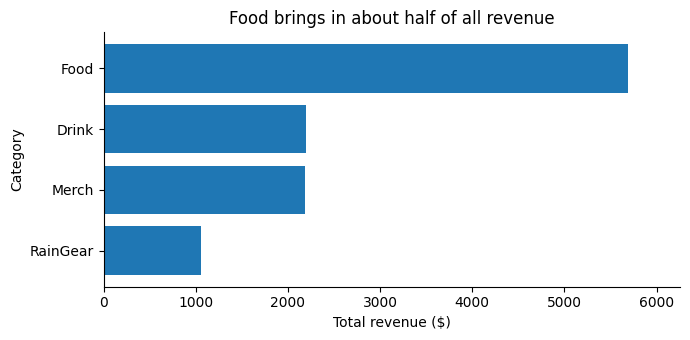

51 % of revenue is Food


In [9]:
# TODO
import matplotlib.pyplot as plt

cat = df.groupby('category')['revenue'].sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(cat.index, cat.values, color='tab:blue')
ax.set_xlim(0, cat.max() * 1.1)
ax.set_title('Food brings in about half of all revenue')
ax.set_xlabel('Total revenue ($)')
ax.set_ylabel('Category')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()
print(round(cat['Food'] / cat.sum() * 100), '% of revenue is Food')

**Caption:** Food is ~half of revenue, so stock and staff the food stands first

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

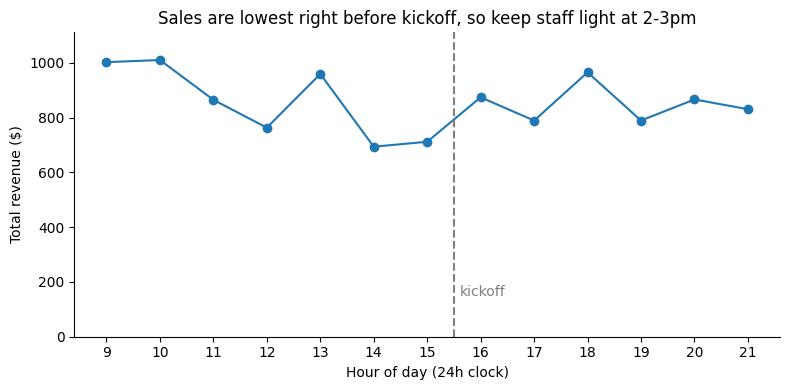

In [10]:
# TODO
hr = df.groupby('hour')['revenue'].sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hr.index, hr.values, marker='o', color='tab:blue')
ax.axvline(15.5, color='gray', linestyle='--')
ax.text(15.6, 150, 'kickoff', color='gray')
ax.set_ylim(0, hr.max() * 1.1)
ax.set_title('Sales are lowest right before kickoff, so keep staff light at 2-3pm')
ax.set_xlabel('Hour of day (24h clock)')
ax.set_ylabel('Total revenue ($)')
ax.set_xticks(hr.index)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Caption:** This is used to help set up shift schedules: more employees are needed during the time that gates first open (9-10am) as well as right before the game starts (kickoff), and fewer employees are needed between 2-3 pm.



### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

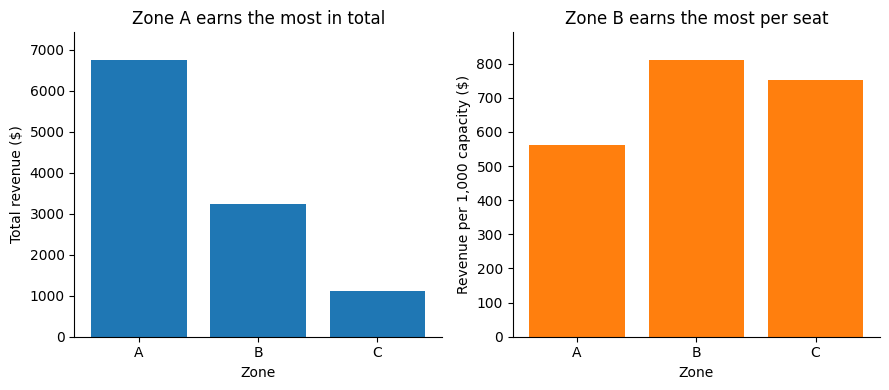

In [11]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacity
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
raw = df.groupby('zone')['revenue'].sum()
per = raw / pd.Series(zone_capacity) * 1000   # $ per 1,000 seats of capacity

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 4))
a1.bar(raw.index, raw.values, color='tab:blue')
a1.set_ylim(0, raw.max() * 1.1)
a1.set_title('Zone A earns the most in total')
a1.set_xlabel('Zone')
a1.set_ylabel('Total revenue ($)')
a2.bar(per.index, per.values, color='tab:orange')
a2.set_ylim(0, per.max() * 1.1)
a2.set_title('Zone B earns the most per seat')
a2.set_xlabel('Zone')
a2.set_ylabel('Revenue per 1,000 capacity ($)')
for a in (a1, a2):
    for s in ['top', 'right']:
        a.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Caption, and which panel I would present:** I'd show the manager of vendors per-capacity panel for Zone A, the largest area, and the raw panel for each zone to show total money brought in by that zone.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

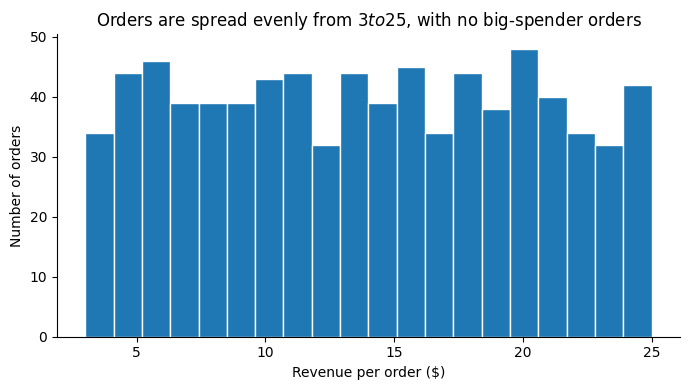

In [12]:
# TODO
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['revenue'], bins=20, color='tab:blue', edgecolor='white')
ax.set_title('Orders are spread evenly from $3 to $25, with no big-spender orders')
ax.set_xlabel('Revenue per order ($)')
ax.set_ylabel('Number of orders')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Caption:** Small orders evenly spread, so more revenue has to come from more orders than just a few very large orders.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

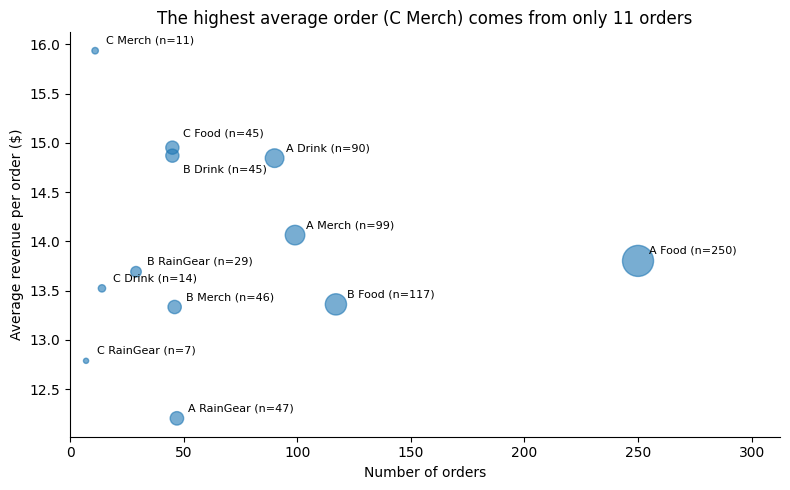

In [13]:
# TODO
g = df.groupby(['zone', 'category'])['revenue'].agg(['mean', 'count']).reset_index()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(g['count'], g['mean'], s=g['count'] * 2, alpha=0.6, color='tab:blue')
for _, r in g.iterrows():
    dy = 8 if (r['zone'], r['category']) == ('C', 'Food') else (-12 if (r['zone'], r['category']) == ('B', 'Drink') else 5)
    ax.annotate(f"{r['zone']} {r['category']} (n={r['count']})", (r['count'], r['mean']),
                textcoords='offset points', xytext=(8, dy), fontsize=8)
ax.set_xlim(0, g['count'].max() * 1.25)
ax.set_title('The highest average order (C Merch) comes from only 11 orders')
ax.set_xlabel('Number of orders')
ax.set_ylabel('Average revenue per order ($)')
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Caption:** Don't put money behind a zone/category with a high average unless it has enough orders to trust.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [14]:
scores = {
    'chart 1 (category)': 6,     # TODO: out of 6
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 5,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      5/6  [ok]

average: 5.8/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

**a)** Chart 3 changed my mind about the best zone. Although Chart 1 and the raw panel show Zone A as having the highest total sales, on a per seat basis, Zone B is better. Chart 2 was the most difficult to title because of the flat sales hours, so I came up with "Sales are lowest right before kick-off".

**b)** Raw view is best when looking for the total amount of money that each zone brings in for things such as total sales or staffing of the biggest zone. Per-capacity view is best when comparing different sized zones such as adding more vendors to various zones because it shows which zone is performing best for its size.